# Imports

In [ ]:
#Usuals
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys
from zipfile import ZipFile
from datetime import datetime
from zoneinfo import ZoneInfo
import re
import json

In [ ]:
#sklearn
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
#ANN
#import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, LSTM, InputLayer
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import RootMeanSquaredError

# Check WRF data errors

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def rmse(predictions, targets):
    return np.nanmean((predictions - targets) ** 2) ** .5

def bias(predictions, targets):
    return np.nanmean(predictions - targets)

pre_error_df = pd.read_pickle('/content/Forestal-resultados_RM-BIA.pkl')
pre_error_df

,Grupo,Variable,Día 1 (RMSE),Día 1 (Bias),Día 2 (RMSE),Día 2 (Bias),Día 3 (RMSE),Día 3 (Bias)
0,G-491-S2m,T,2.883043,-0.858252,3.175170,-0.758137,3.241176,-0.865688
1,G-491-Z0,T,2.968774,-0.478151,3.290730,-0.417843,3.326887,-0.495135
2,G-530-S2m,T,2.844761,-0.621276,3.171398,-0.534757,3.246492,-0.644711
3,G-530-Z0,T,2.928968,-0.265108,3.258799,-0.222270,3.303391,-0.307284
4,G-491-S2m,rh,17.851231,-5.647336,20.246662,-6.905286,20.560999,-7.242146
5,G-491-Z0,rh,19.917374,-7.933956,22.272138,-8.951236,22.598523,-9.322157
6,G-530-S2m,rh,18.248189,-6.330980,20.712238,-7.470553,21.132704,-7.763601
7,G-530-Z0,rh,20.151667,-8.578977,22.482838,-9.478853,22.874236,-9.805647
8,G-491-S2m,td,3.635377,-2.443839,4.037220,-2.712809,4.214361,-2.889702
9,G-491-Z0,td,3.749604,-2.507014,4.151195,-2.773890,4.323052,-2.934679


# Load and filter data
* Also add time signals

In [ ]:
# Import data
dff = pd.read_pickle('/content/Foresta-G-491-S2m.pkl')

# Filter only the d2 forecasting
temp_df = pd.DataFrame({'obs_temp' : dff[('Observaciones', 'T')],
                   'WRF_temp' : dff[('Día 2', 'T')],
                   'WRF_td' : dff[('Día 2', 'td')],
                   'WRF_rh' : dff[('Día 2', 'rh')],
                   'WRF_ws' : dff[('Día 2', 'ws')],
                   'WRF_wd' : dff[('Día 2', 'wd')]})


# Build time signals
temp_df['Seconds'] = temp_df.index.map(pd.Timestamp.timestamp)

day = 24*60*60
year = 365.2422 * day

temp_df['Day sin'] = np.sin(temp_df['Seconds'] * (2 * np.pi / day))     #sin(x * 2pi * f)
temp_df['Day cos'] = np.cos(temp_df['Seconds'] * (2 * np.pi / day))
temp_df['Year sin'] = np.sin(temp_df['Seconds'] * (2 * np.pi / year))
temp_df['Year cos'] = np.cos(temp_df['Seconds'] * (2 * np.pi / year))

# Now we drop the seconds column since its not a good feature for periodicity
temp_df.drop('Seconds', axis=1, inplace=True)
temp_df


,obs_temp,WRF_temp,WRF_td,WRF_rh,WRF_ws,WRF_wd,Day sin,Day cos,Year sin,Year cos
2020-01-03 00:00:00,15.0,11.765656,11.475677,98.945305,0.617653,176.578262,9.267350e-13,1.000000,0.032508,0.999471
2020-01-03 01:00:00,14.0,10.668335,10.437531,99.265160,3.132564,174.418884,2.588190e-01,0.965926,0.033224,0.999448
2020-01-03 02:00:00,14.0,9.129272,8.863800,98.933716,3.146147,232.438431,5.000000e-01,0.866025,0.033940,0.999424
2020-01-03 03:00:00,14.0,9.070374,8.491211,96.828171,3.099442,351.432831,7.071068e-01,0.707107,0.034657,0.999399
2020-01-03 04:00:00,13.0,8.706665,7.856049,95.010460,2.801155,132.974136,8.660254e-01,0.500000,0.035373,0.999374
...,...,...,...,...,...,...,...,...,...,...
2023-12-27 19:00:00,20.0,15.741425,12.820679,83.458916,4.478685,351.870941,-9.659258e-01,0.258819,-0.073684,0.997282
2023-12-27 20:00:00,19.0,16.222229,12.317291,78.248070,4.220447,10.122013,-8.660254e-01,0.500000,-0.072969,0.997334
2023-12-27 21:00:00,18.0,16.589355,12.040955,75.029198,3.798984,11.797519,-7.071068e-01,0.707107,-0.072254,0.997386
2023-12-27 22:00:00,18.0,16.185883,12.159851,77.611206,3.984816,7.568184,-5.000000e-01,0.866025,-0.071539,0.997438


# Regressor trees
* Here we use regressor trees to define regimes where WRF forecast might have a optimal or suboptimal performance, based on the forecasting error
* E.g., If one of the regressor trees splits the data based on the condition rh > .8 and temp > 20°C, then maybe the left branch has lower error than the right branch
* We use WRF_var and obs_var notation

### Prepare features and targets
* Features: 5 WRF and 4 temporal signals
* Target: WRF temperature error

In [ ]:
# features: forecasted WRF vars + time info
X = temp_df[['WRF_temp', 'WRF_td', 'WRF_rh', 'WRF_ws', 'WRF_wd', 'Day sin', 'Day cos', 'Year sin', 'Year cos']]
# target: forecast error
y = temp_df['WRF_temp'] - temp_df['obs_temp']

In [ ]:
#Split: 1 year for training, 1 month for val and the rest for testing

X_train = X.iloc[:8766]
y_train = y.iloc[:8766]
X_val = X.iloc[8766:9486]           #8766+720 = 9486
y_val = y.iloc[8766:9486]
X_test = X.iloc[9486:]
y_test = y.iloc[9486:]
X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape

((8766, 9), (720, 9), (14662, 9), (8766,), (720,), (14662,))

### Train regressor trees
* Put this into a loop to run through different hyperparameters
* The hyperparams define how general/specific the **regimes** are

In [ ]:
##  If u want to train just one regressor  ##
#tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=50)
#tree.fit(X, y)

In [ ]:
# Construcción del random forest

# Initialize and train
rf = RandomForestRegressor(n_estimators=30, random_state=42, max_depth=7)           #Ajustar más hyperparámetros
rf.fit(X_train, y_train)

print('Train Score: ', rf.score(X_train, y_train))                # 1.0 es la nota máxima ; Same as accuracy
print('Validation Score: ', rf.score(X_val, y_val))

# Predict and evaluate
y_pred = rf.predict(X_test)
rmse_post = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)                               # Test vs predcitions

#print(f"RMSE (pre): {rmse_pre:.2f}")
print(f"RMSE (post): {rmse_post:.2f}")
print(f"R²: {r2:.2f}")

Train Score:  0.7113003768956564
Validation Score:  0.21396575374323035
RMSE (post): 4.56
R²: 0.49


### Visualize partial results

In [ ]:
# View the rules (text-based)
#tree = rf.estimators_[0].tree_
#Complete later


### Export most meaninful splits
* Fix this to make a loop

In [ ]:
def extract_clean_tree_rules(tree, feature_names, max_depth=2):
    raw_rules = export_text(tree, feature_names=feature_names, max_depth=max_depth).splitlines()
    rule_rows = []

    for line in raw_rules:
        depth = line.count('|   ')
        if depth > max_depth:
            continue

        # Remove indentation
        clean_line = line.replace('|   ', '')
        match = re.match(r'(.+?) (<=|>) ([\d\.\-e]+)', clean_line)
        if match:
            feature = match.group(1).strip()
            comparator = match.group(2)
            threshold = float(match.group(3))
            rule_rows.append({
                'depth': depth,
                'feature': feature,
                'comparator': comparator,
                'threshold': threshold
            })

    return pd.DataFrame(rule_rows)

var = 'temp'
# Write the first 2 levels to a file
with open(f"{var}_tree_rules.txt", "w") as f:
    tree_rules = export_text(tree, feature_names=list(X.columns), max_depth=2)
    f.write(tree_rules)

tree_df = extract_clean_tree_rules(tree, list(X.columns), max_depth=2)
tree_df['temp'] = var       # tag with the variable (temp, rh, etc.)

final_rules_df = tree_df

# Use this when fitting trees inside the loop
#all_tree_dfs.append(tree_df)
#final_rules_df = pd.concat(all_tree_dfs, ignore_index=True)

# Save to CSV
final_rules_df.to_csv("clean_wrf_tree_rules.csv", index=False)

### Optional: export some pictures
* Maybe there are some very representative trees that we want to show as an image
* Fix this so u can classify and list the different trees, this way u can make some statistic over it.
* To access a regressor just use

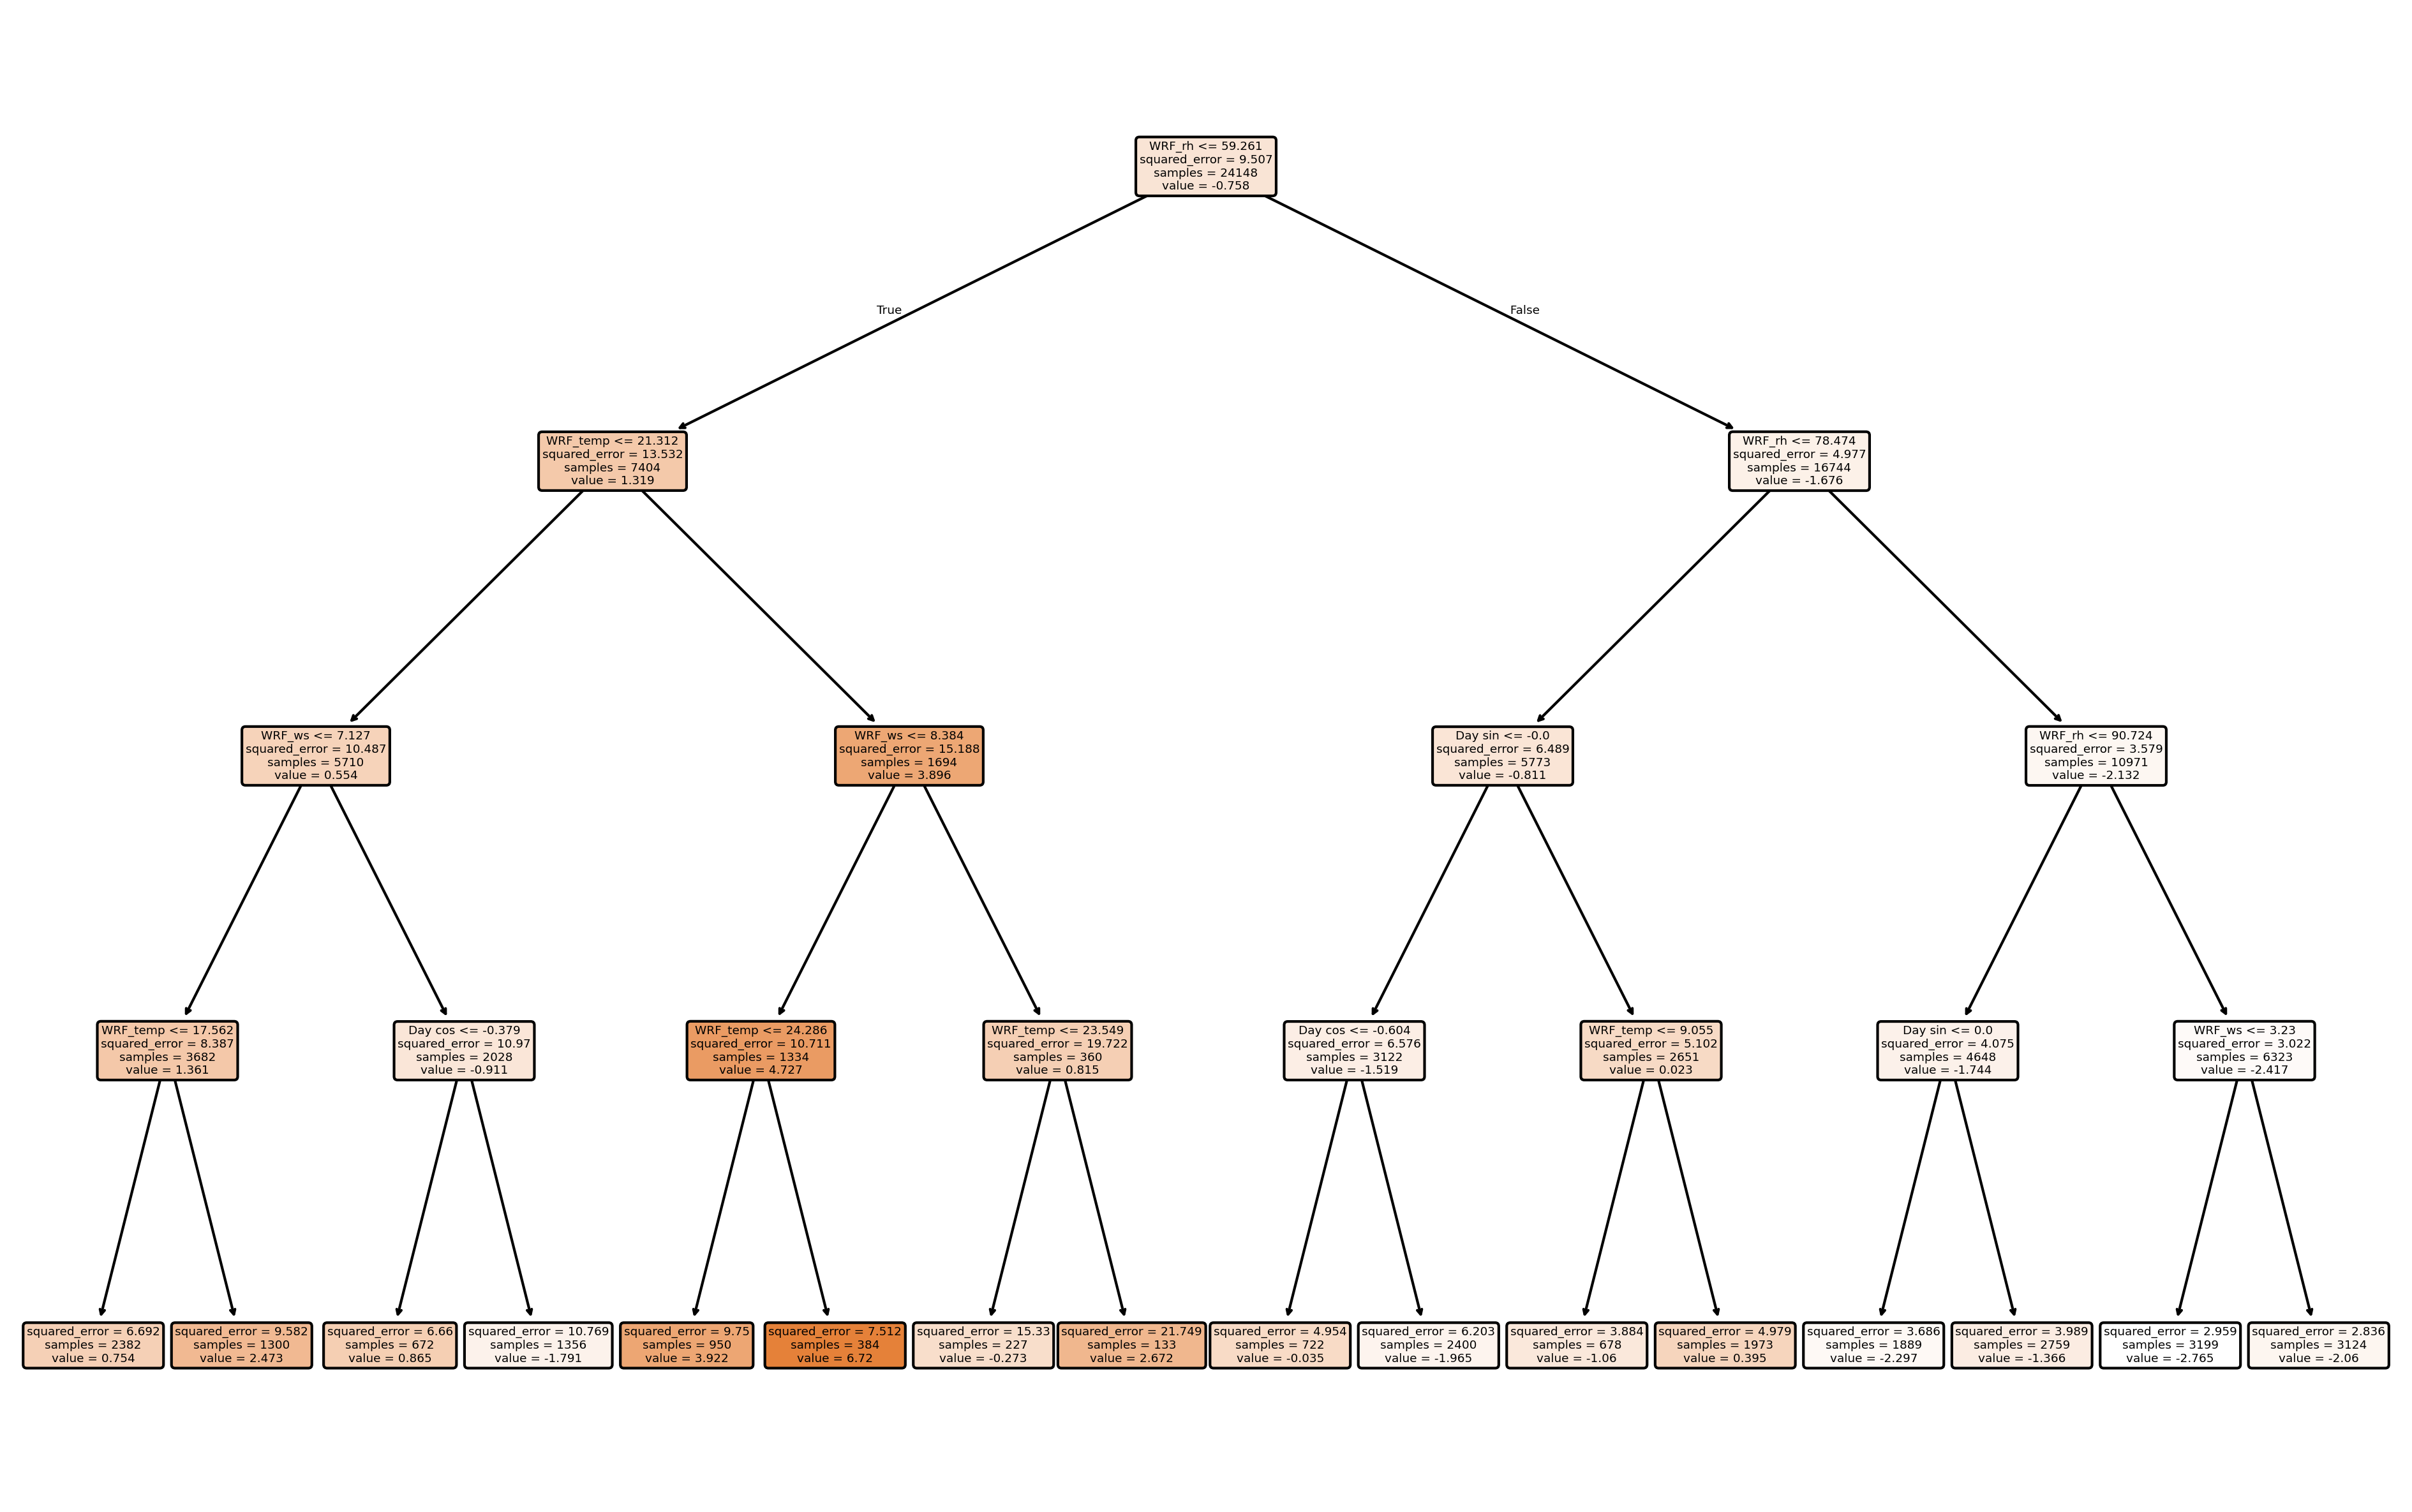

In [ ]:
tree = rf.estimators_[0].tree_

# Feature names (optional, for nicer output)
feature_names = [f"feature_{i}" for i in range(X.shape[1])]

# Loop over nodes
for node_id in range(tree.node_count):
    if tree.children_left[node_id] != tree.children_right[node_id]:  # not a leaf
        split_feature = tree.feature[node_id]
        threshold = tree.threshold[node_id]
        print(f"Node {node_id}: {feature_names[split_feature]} <= {threshold:.2f}")
    else:
        print(f"Leaf {node_id}: Predict = {tree.value[node_id][0][0]:.2f}")

    print(f"  Samples: {tree.n_node_samples[node_id]}")
    print(f"  MSE (impurity): {tree.impurity[node_id]:.2f}\n")

plt.figure(figsize=(16, 10), dpi=300)
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.show()

**Note**: Train separately per variable and maybe define different model for different variables

# Simple ANN architecture exploration

In [ ]:
# Play around with the number of features

X = temp_df[['WRF_temp','WRF_td', 'WRF_rh', 'WRF_ws', 'WRF_wd','Day cos', 'Year cos', 'Day sin', 'Year sin']]
y = temp_df['WRF_temp'] - temp_df['obs_temp']

#Split
X_train = X.iloc[:8766]             # [one year]
y_train = y.iloc[:8766]
X_val = X.iloc[8766:9486]           #8766+720 = 9486  [1 month]
y_val = y.iloc[8766:9486]
X_test = X.iloc[9486:]              # [20.4 months]
y_test = y.iloc[9486:]
X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape ,len(X.columns)

((8766, 9), (720, 9), (14662, 9), (8766,), (720,), (14662,), 9)

In [ ]:
# Build model

model_num = '6'                              #Make sure to change this before running
model1 = Sequential()
model1.name = 'ErrorANN'+model_num
model1.add(InputLayer((len(X.columns),)))
model1.add(Dense(16, 'relu'))
model1.add(Dense(8, 'tanh'))
model1.add(Dense(1, activation='linear'))

model1.summary()

Model: "ErrorANN6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Checkpoint and some hyperparameters
cp = ModelCheckpoint('ErrorModel/model'+model_num+'.keras', save_best_only=True)
L_RATE = 0.0006
model1.compile(loss=MeanSquaredError(), optimizer=Adam(learning_rate=L_RATE), metrics=[RootMeanSquaredError()])
EPOCHS = 16

In [ ]:
with open('ErrorModel/model'+model_num+'_summary.txt', 'a') as f:                       # 'w' mode overwrites it
    f.write(f"{datetime.now(ZoneInfo('America/Santiago'))}\n")
    model1.summary(print_fn=lambda x: f.write(x + '\n'))
    f.write(f"Learning rate: {L_RATE}\n")
    f.write(f"Epochs: {EPOCHS}\n")
    f.write(f"Train size: {len(X_train)} [hrs]\n")
    f.write(f"Val size: {len(X_val)} [hrs]\n")
    f.write(f"Test size: {len(X_test)} [hrs]\n")

In [ ]:
# Fit model     (Better do it down there, as it writes it as well)
model1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, callbacks=[cp])

Epoch 1/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 13.9252 - root_mean_squared_error: 3.7286 - val_loss: 7.3283 - val_root_mean_squared_error: 2.7071
Epoch 2/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 9.5217 - root_mean_squared_error: 3.0854 - val_loss: 5.7453 - val_root_mean_squared_error: 2.3969
Epoch 3/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.7725 - root_mean_squared_error: 2.9612 - val_loss: 5.4510 - val_root_mean_squared_error: 2.3347
Epoch 4/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.2992 - root_mean_squared_error: 2.8803 - val_loss: 5.2799 - val_root_mean_squared_error: 2.2978
Epoch 5/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 7.6325 - root_mean_squared_error: 2.7621 - val_loss: 5.1524 - val_root_mean_squared_error: 2.2699
Epoch 6/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6.9912 - root_mean_squared_error: 2.6437 - val_loss: 5.0724 - val_root_mean_squared_error: 2.2522
Epoch 7/25
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [ ]:
history_model_1 = model1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, callbacks=[cp])

Epoch 1/16
274/274 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 10.9166 - root_mean_squared_error: 3.3015 - val_loss: 6.6383 - val_root_mean_squared_error: 2.5765
Epoch 2/16
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 8.2297 - root_mean_squared_error: 2.8683 - val_loss: 6.1500 - val_root_mean_squared_error: 2.4799
Epoch 3/16
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 7.5577 - root_mean_squared_error: 2.7487 - val_loss: 6.3100 - val_root_mean_squared_error: 2.5120
Epoch 4/16
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 7.5367 - root_mean_squared_error: 2.7450 - val_loss: 5.8349 - val_root_mean_squared_error: 2.4156
Epoch 5/16
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 7.0840 - root_mean_squared_error: 2.6611 - val_loss: 5.7843 - val_root_mean_squared_error: 2.4051
Epoch 6/16
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6.6470 - root_mean_squared_error: 2.5769 - val_loss: 5.5720 - val_root_mean_squared_error: 2.3605
Epoch 7/16
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [ ]:
# Saving option 1
# Get the dictionary containing each metric and the loss for each epoch
history_dict = history_model_1.history
# Save it under the form of a json file
json.dump(history_dict, open('ErrorModel/model'+model_num+'_fit.txt', 'a'))

# Write a pkl from history dict
history_df = pd.DataFrame(history_dict)
history_df.to_pickle('ErrorModel/model'+model_num+'_fit.pkl')


In [ ]:
# # Saving option 2
original_stdout = sys.stdout
with open('ErrorModel/model'+model_num+'_fit.txt', 'a') as f:
    sys.stdout = f
    model1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, callbacks=[cp])
    sys.stdout = original_stdout

In [ ]:
#Make predictions (build this up into a function)
train_predictions = model1.predict(X_train).flatten()
val_predictions = model1.predict(X_val).flatten()
test_predictions = model1.predict(X_test).flatten()

274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
459/459 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [ ]:
#y_train = y_train.to_numpy()           #Run just once
#y_val = y_val.to_numpy()
#y_test = y_test.to_numpy()

train_results = pd.DataFrame(data={'Train Predictions': train_predictions, 'Real Values': y_train.flatten()})
val_results = pd.DataFrame(data={'Val Predictions': val_predictions.flatten(), 'Real Values': y_val.flatten()})
test_results = pd.DataFrame(data={'Test Predictions': test_predictions.flatten(), 'Real Values': y_test.flatten()})

<Axes: >

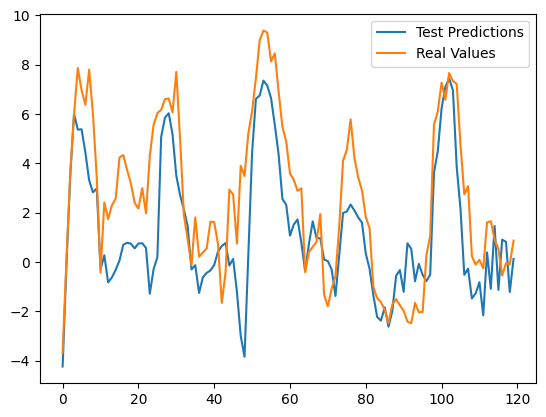

In [ ]:
test_results[:120].plot()

* Al parecer si usas solo sin o cos, aparecen cotas muy marcadas que impiden seguir la curva real, por eso es que hay que utilizar ambos, seno y coseno

In [ ]:
# Setear datetime index al dataframe de resultados
test_results.index = temp_df[-14662:].index

<Axes: >

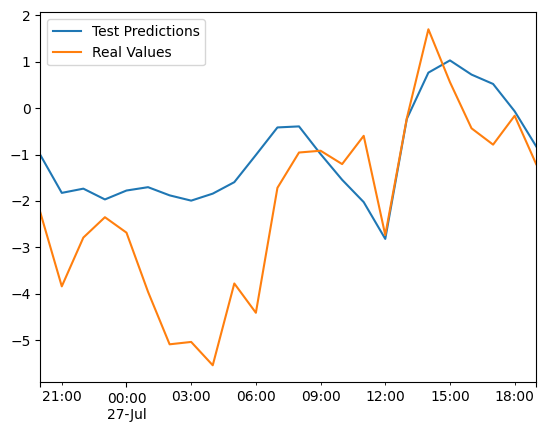

In [ ]:
test_results[200:224].plot()

Añadir el ajuste a los datos para comparar Bias y RMSE

In [ ]:
def rmse(predictions, targets):
    return np.sqrt(((predictions - targets) ** 2).mean())

def bias(predictions, targets):
    return np.mean(predictions - targets)

y_test_real = temp_df[-14662:]['obs_temp']
y_test_pre = temp_df[-14662:]['WRF_temp']
y_test_post = y_test_pre - test_predictions
print("Pre: ", rmse(y_test_pre, y_test_real), bias(y_test_pre, y_test_real))
print("Post: ", rmse(y_test_post, y_test_real), bias(y_test_post, y_test_real))

Pre:  3.079865179563452 -0.71969018534706
Post:  2.1390558109608055 0.13243488607197176


* Okay, nice results.
* Now for the real part, try this model with some other data.
* 1st let's try it on Forestal 530 S2m, día 2
* Input: 'WRF_temp','WRF_td', 'WRF_rh', 'WRF_ws', 'WRF_wd','Day cos', 'Year cos', 'Day sin', 'Year sin'
* Notice that we didn't normalize and we didnt adjust the batch size, also we still need to pllt the learnijg curves for train and validarion sets , and make sure aour model i

In [ ]:
def add_time_signals(df, day, var):                     #De momento solo para la temperatura
    '''We don't want to keep the multi-index'''         #Down there we have a more general function
    signal_df = pd.DataFrame({'obs_temp' : df[('Observaciones', var)],
                   'WRF_temp' : df[('Día '+day, 'T')],
                   'WRF_td' : df[('Día '+day, 'td')],
                   'WRF_rh' : df[('Día '+day, 'rh')],
                   'WRF_ws' : df[('Día '+day, 'ws')],
                   'WRF_wd' : df[('Día '+day, 'wd')]})

    signal_df['Seconds'] = df.index.map(pd.Timestamp.timestamp)
    day = 24*60*60
    year = 365.2422 * day
    signal_df['Day sin'] = np.sin(signal_df['Seconds'] * (2 * np.pi / day))
    signal_df['Day cos'] = np.cos(signal_df['Seconds'] * (2 * np.pi / day))
    signal_df['Year sin'] = np.sin(signal_df['Seconds'] * (2 * np.pi / year))
    signal_df['Year cos'] = np.cos(signal_df['Seconds'] * (2 * np.pi / year))
    signal_df.drop('Seconds', axis=1, inplace=True)
    return signal_df

In [ ]:
def rmse(predictions, targets):
    return np.sqrt(((predictions - targets) ** 2).mean())

def bias(predictions, targets):
    return np.mean(predictions - targets)

In [ ]:
# Load data (build this up into a function)
# Make a funciton to add the time signals

dff = pd.read_pickle('/content/Foresta-G-530-S2m.pkl')

#add time signals
dff = add_time_signals(dff, day='3', var='T')
dff

pre_rmse = rmse(dff['WRF_temp'], dff['obs_temp'])
pre_bias = bias(dff['WRF_temp'], dff['obs_temp'])
print(f"Pre RMSE = {pre_rmse:.4f}")
print(f"Pre Bias = {pre_bias:.4f}")

Pre RMSE = 3.2465
Pre Bias = -0.6447


In [ ]:
#Make error prediction
error_predictions = model1.predict(dff[['WRF_temp','WRF_td', 'WRF_rh', 'WRF_ws', 'WRF_wd','Day cos', 'Year cos', 'Day sin', 'Year sin']])
predictions = (dff['WRF_temp'] - error_predictions.flatten()).to_numpy()

post_rmse = rmse(predictions, dff['obs_temp'])
post_bias = bias(predictions, dff['obs_temp'])
print(f"Post RMSE = {post_rmse:.4f}")
print(f"Post Bias = {post_bias:.4f}")

755/755 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Post RMSE = 2.2464
Post Bias = 0.1963


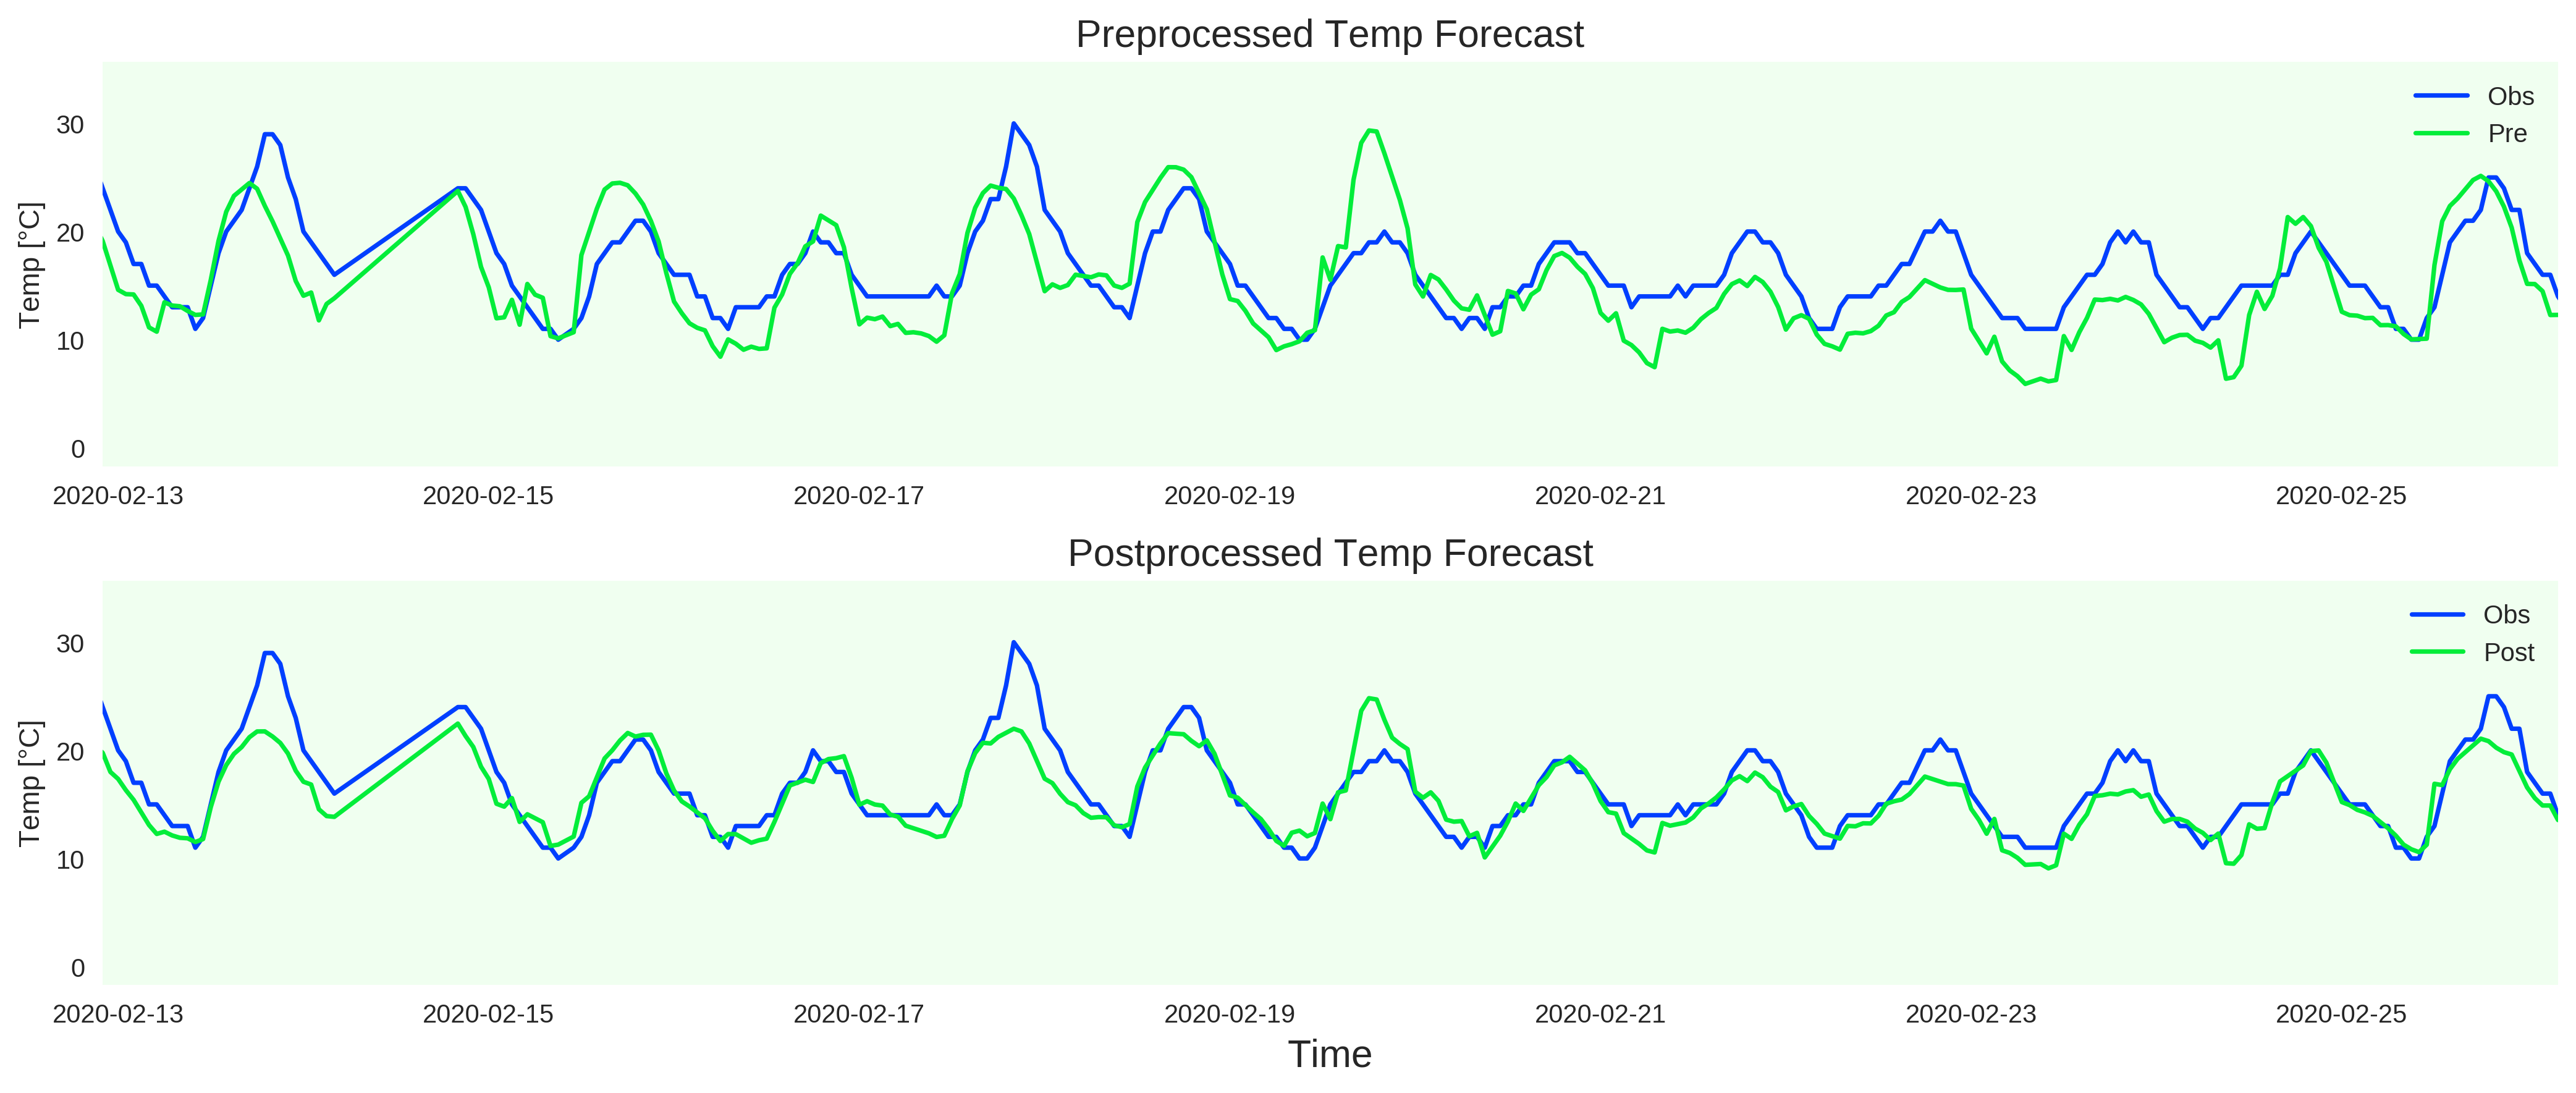

In [ ]:
# Plot Pre and post to see the comparison

start = 500
interval = 300
color='honeydew'

plt.style.use('seaborn-v0_8-bright')
fig, axes = plt.subplots(2, 1, figsize=(14, 6), dpi=300)

axes[0].set_ylabel('Temp [°C]')
axes[0].set_title('Preprocessed Temp Forecast', fontsize=15)
axes[0].plot(dff['obs_temp'],label="Obs")
axes[0].plot(dff['WRF_temp'],label="Pre")
axes[0].set_xlim(dff.index[start], dff.index[start+interval])
axes[0].legend()
axes[0].grid()
axes[0].set_facecolor(color)

axes[1].set_ylabel('Temp [°C]')
axes[1].set_title('Postprocessed Temp Forecast',fontsize=15)
axes[1].set_xlabel('Time', fontsize=15)
axes[1].plot(dff['obs_temp'], label="Obs")
axes[1].plot(dff['WRF_temp'] - error_predictions.flatten(), label="Post")
axes[1].set_xlim(dff.index[start], dff.index[start+interval])
axes[1].legend()
axes[1].grid()
axes[1].set_facecolor(color)

#Set seaborn style
plt.tight_layout()
plt.show()


In [ ]:
#save plot
fig.savefig("temp_Forestal530s2m_PPmodel1.png")

A continuación el código (limpio) para cargar el modelo y exportar resultados
* Como argumento tenemos el pkl de entrada, en formato usual de multi-index, y el modelo que queremos utilizar (como cada modelo corresponde a una sola variable, no es necesario un argumento para la variable)
* Se exportan tanto el df con la entrada corregida como los errores respecto al tiempo (este punto verlo luego)  

In [ ]:
#Load .keras model
model22 = load_model('model1.keras')

# Load data (build this up into a function)
#dff = pd.read_pickle('/content/Foresta-G-530-Z0.pkl')
dff = pd.read_pickle('/content/Foresta-G-491-S2m.pkl')

#add time signals
dff = add_time_signals(dff, day='3', var='T')
dff

pre_rmse = rmse(dff['WRF_temp'], dff['obs_temp'])
pre_bias = bias(dff['WRF_temp'], dff['obs_temp'])
print(f"Pre RMSE = {pre_rmse:.4f}")                             #Quitar prints luego
print(f"Pre Bias = {pre_bias:.4f}")

Pre RMSE = 3.2412
Pre Bias = -0.8657


In [ ]:
#Make error prediction
error_predictions = model22.predict(dff[['WRF_temp','WRF_td', 'WRF_rh', 'WRF_ws', 'WRF_wd','Day cos', 'Year cos', 'Day sin', 'Year sin']])
predictions = (dff['WRF_temp'] - error_predictions.flatten()).to_numpy()

post_rmse = rmse(predictions, dff['obs_temp'])
post_bias = bias(predictions, dff['obs_temp'])
print(f"Post RMSE = {post_rmse:.4f}")
print(f"Post Bias = {post_bias:.4f}")

755/755 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  
Post RMSE = 2.2307
Post Bias = -0.1497


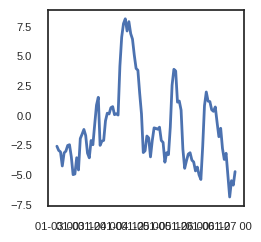

In [ ]:
plt.plot(dff['WRF_temp'][:100] - dff['obs_temp'][:100])             #WRF Error

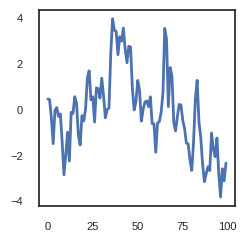

In [ ]:
plt.plot(predictions[:100]-dff['obs_temp'][:100].to_numpy().flatten())              #Corrected WRF

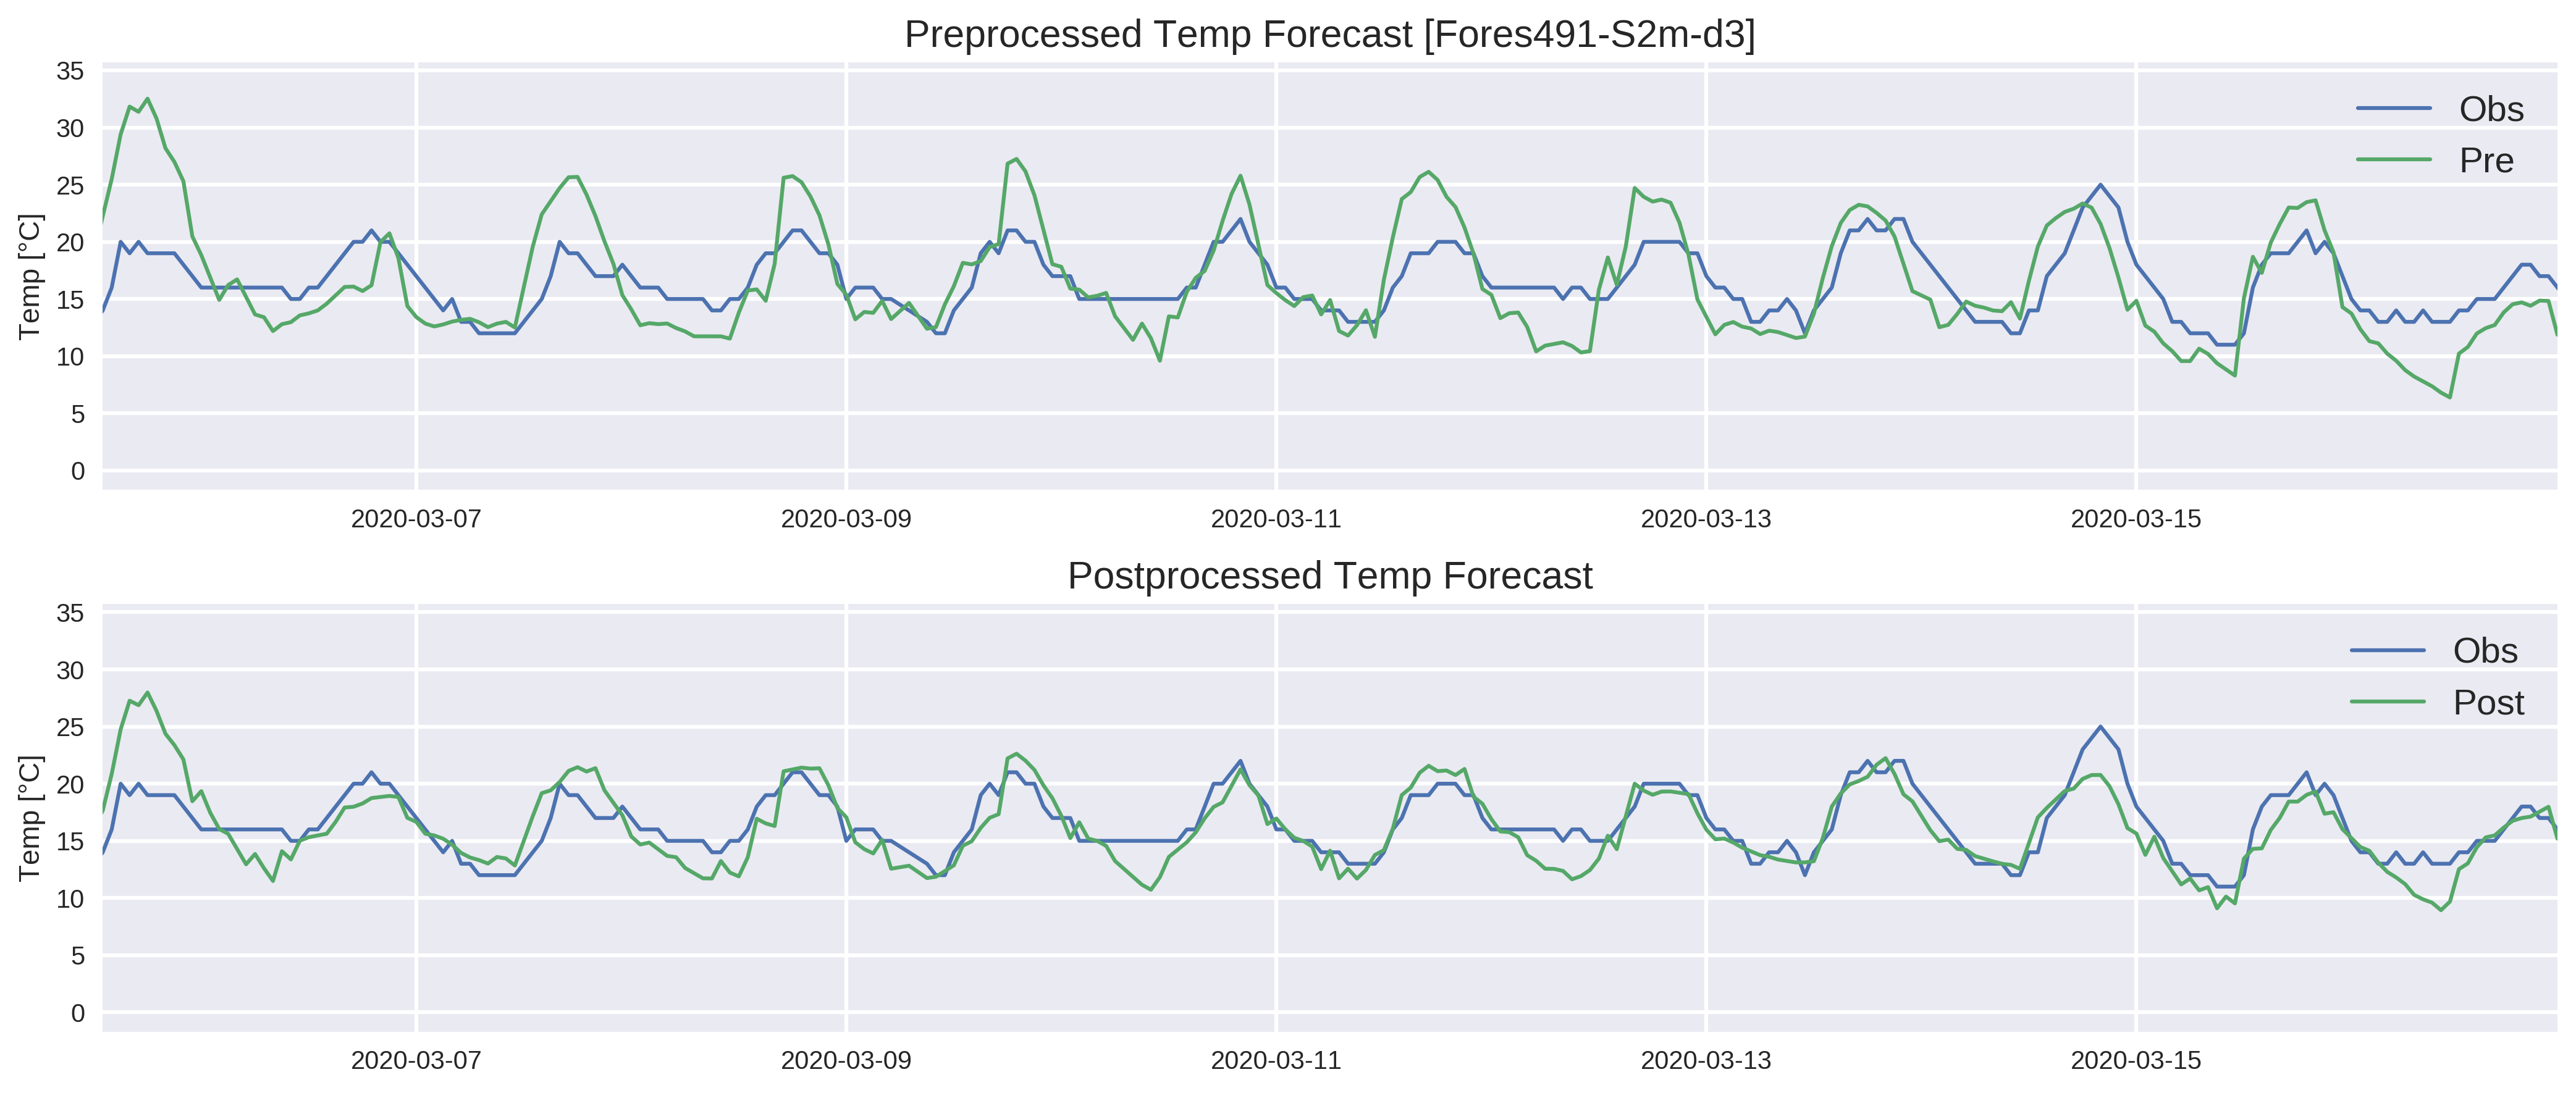

In [ ]:
# Make this prettier
import seaborn as sns

start = 1000
interval = 270
#color='lavender'

plt.style.use('seaborn-v0_8')
fig, axes = plt.subplots(2, 1, figsize=(14, 6), dpi=300)

axes[0].set_ylabel('Temp [°C]')
axes[0].set_title('Preprocessed Temp Forecast [Fores491-S2m-d3]', fontsize=15)
axes[0].plot(dff['obs_temp'],label="Obs", linewidth=1.5)
axes[0].plot(dff['WRF_temp'],label="Pre",linewidth=1.5)
axes[0].set_xlim(dff.index[start], dff.index[start+interval])
axes[0].legend(fontsize=14)
axes[0].grid(linewidth=1.5)#, linestyle="--")
#axes[0].set_facecolor(color)

axes[1].set_ylabel('Temp [°C]')
axes[1].set_title('Postprocessed Temp Forecast',fontsize=15)
#axes[1].set_xlabel('Time', fontsize=15)
axes[1].plot(dff['obs_temp'], label="Obs", linewidth=1.5)
axes[1].plot(dff['WRF_temp'] - error_predictions.flatten(), label="Post", linewidth=1.5)
axes[1].set_xlim(dff.index[start], dff.index[start+interval])
axes[1].legend(fontsize=14)
axes[1].grid(linewidth=1.5)#, linestyle="--")
#axes[1].set_facecolor(color)

plt.tight_layout()
plt.show()


## Needed Upgrades
* Make another function to be able to select other variables, maybe one model can handle more that just one variable or maybe we can ask for a different input or output vector

In [ ]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [ ]:
# fit pkl reading

fit_df = pd.read_pickle('ErrorModel/model6_fit.pkl')
fit_df[fit_df['val_loss']==fit_df['val_loss'].min()]

,loss,root_mean_squared_error,val_loss,val_root_mean_squared_error
15,5.170687,2.273914,4.34145,2.083615


# Model1_temp_5+4=1

## Functions

In [ ]:
def add_time_signals(df, day, var):
    '''We don't want to keep the multi-index'''
    if var == 'T':
        var2 = 'temp'
    else:
        var2 = var

    signal_df = pd.DataFrame({'obs_'+var2 : df[('Observaciones', var)],
                   'WRF_temp' : df[('Día '+day, 'T')],
                   'WRF_td' : df[('Día '+day, 'td')],
                   'WRF_rh' : df[('Día '+day, 'rh')],
                   'WRF_ws' : df[('Día '+day, 'ws')],
                   'WRF_wd' : df[('Día '+day, 'wd')]})

    signal_df['Seconds'] = df.index.map(pd.Timestamp.timestamp)
    day = 24*60*60
    year = 365.2422 * day
    signal_df['Day sin'] = np.sin(signal_df['Seconds'] * (2 * np.pi / day))
    signal_df['Day cos'] = np.cos(signal_df['Seconds'] * (2 * np.pi / day))
    signal_df['Year sin'] = np.sin(signal_df['Seconds'] * (2 * np.pi / year))
    signal_df['Year cos'] = np.cos(signal_df['Seconds'] * (2 * np.pi / year))
    signal_df.drop('Seconds', axis=1, inplace=True)
    return signal_df

def rmse(predictions, targets):
    return np.sqrt(((predictions - targets) ** 2).mean())

def bias(predictions, targets):
    return np.mean(predictions - targets)

## Load model and make predictions

Obs: Para el post debo hacer un arreglo para ver como agrupar por hora, probablemente sumar cada 24 elementos o así, y luego dividir o bien armar un df nuevo y concatenar los valores corregidos (esto parece una mejor opción)


---


**Extensión del experimento 1**
* Aplicar modelo en estaciones más alejadas de la estación de entrenamiento (forestal 491). En este caso Molo y Montemar (1044)

*


In [ ]:
d# Load .keras model
model_number = 3
model22 = load_model(f'model{model_number}.keras')

# Load data (build this up into a function!)
#file_name = 'Foresta-G-530-Z0'
file_name = 'Foresta-G-530-S2m'
#file_name = 'Foresta-G-491-S2m'
#Para los de montemar primero debo preprocesar los datos
dff = pd.read_pickle(f'/content/{file_name}.pkl')

# Add time signals
day = '1'
dff = add_time_signals(dff, day=day, var='T')
dff

#pre temperature metric
pre_rmse = rmse(dff['WRF_temp'], dff['obs_temp'])
pre_bias = bias(dff['WRF_temp'], dff['obs_temp'])
#pre_diurnal_bias = dff.groupby(dff.index.hour)['WRF_temp'].mean() - dff.groupby(dff.index.hour)['obs_temp'].mean()  #check this formula

## Experimento: pasarle datos de manera desordenada (respecto a la fecha)
random_state = 42
shuffled_df = dff.sample(frac=1).reset_index(drop=True)
dff = shuffled_df

#Make predictions: error = wrf-obs
X_test = dff[['WRF_temp','WRF_td', 'WRF_rh', 'WRF_ws', 'WRF_wd','Day cos', 'Year cos', 'Day sin', 'Year sin']]
dff["Corrected_T"] = dff["WRF_temp"] - model22.predict(X_test).flatten()

#post temperatures metrics
post_rmse = rmse(dff["Corrected_T"], dff['obs_temp'])
post_bias = bias(dff["Corrected_T"], dff['obs_temp'])
#post_diurnal_bias = dff.groupby(dff.index.hour)['Corrected_T'].mean() - dff.groupby(dff.index.hour)['obs_temp'].mean()

print(f"Pre RMSE = {pre_rmse:.5f}")                             #Quitar prints luego
print(f"Pre Bias = {pre_bias:.5f}")
print(f"post RMSE = {post_rmse:.5f}")
print(f"post Bias = {post_bias:.5f}")               #append this to s dict or dataframe

755/755 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Pre RMSE = 2.84476
Pre Bias = -0.62128
post RMSE = 2.06331
post Bias = 0.00047


# Some results and plot ideas

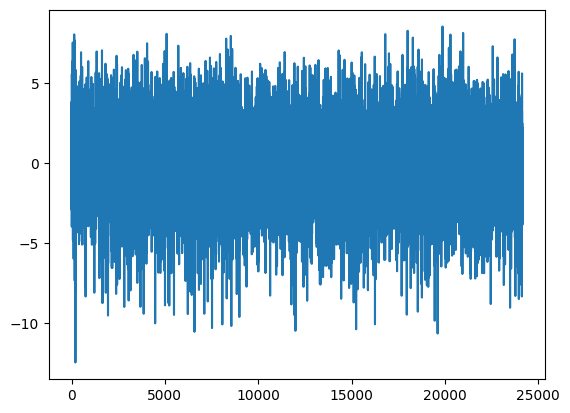

In [ ]:
plt.plot((dff["Corrected_T"]-dff["obs_temp"]).to_numpy())
plt.show()

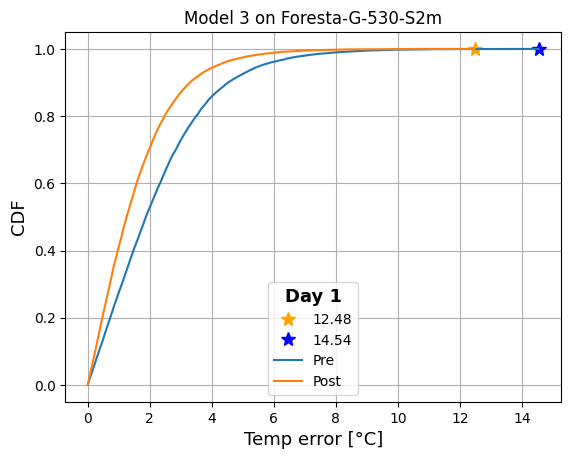

In [ ]:
#Build CDF for pre_temp_error and for post_temp_error
# Make this a function (done)

pre_temp_error = np.abs(dff['WRF_temp'] - dff['obs_temp'])
post_temp_error = np.abs(dff["Corrected_T"] - dff['obs_temp'].to_numpy())

pre_sorted = np.sort(pre_temp_error)
pre_cdf = np.arange(len(pre_sorted)) / len(pre_sorted)
post_sorted = np.sort(post_temp_error)
post_cdf = np.arange(len(post_sorted)) / len(post_sorted)
plt.plot(post_sorted[-1],post_cdf[-1], "*", color="orange", markersize=10, label=round(post_sorted[-1],2))
plt.plot(pre_sorted[-1], pre_cdf[-1], "b*", markersize=10, label=round(pre_sorted[-1],2))

#Plot CDFs
plt.title(f"Model {model_number} on {file_name}")
plt.plot(pre_sorted, pre_cdf, label='Pre')
plt.plot(post_sorted, post_cdf, label='Post')
plt.xlabel("Temp error [°C]", fontsize=13)
plt.ylabel("CDF", fontsize=13)
plt.legend(title=f"Day {day}", title_fontproperties={'weight': 'bold', 'size':'13'}, loc='lower center')
plt.grid()

#save fig
plt.savefig(f"CDF_Model{model_number}_Day{day}_Shuffle-{file_name}.png", dpi=400)
plt.show()

#Maybe add more ticks


**Comments**
* We see some area between the curves, but not too much, maybe because the model was already not too bad
* Also notice that the post_max error is less than the pre_max

# The actual plot

## def function

Notice that for this fucntion to work we need to have a datetime index

In [ ]:
## Make a figure with the cdf and the diurnal bias of the error

def plot_errors(df, day, file_name, model_number, figsize=(7, 6), save=0):
    '''Corrected dataframe, data source info and model'''

    n=14          # fontsize

    fig, axes = plt.subplots(1, 2,figsize=figsize)
    plt.suptitle(f"CDF and Diurnal Bias | Model {model_number} on {file_name} day {day}", fontsize=14, fontweight="bold", y=1)

    # CDF for absolute errors
    pre_temp_error = np.abs(df['WRF_temp'] - df['obs_temp'])
    post_temp_error = np.abs(df["Corrected_T"] - df['obs_temp'].to_numpy())

    pre_sorted = np.sort(pre_temp_error)
    pre_cdf = np.arange(len(pre_sorted)) / len(pre_sorted)
    post_sorted = np.sort(post_temp_error)
    post_cdf = np.arange(len(post_sorted)) / len(post_sorted)

    #Plot CDFs
    axes[0].plot(pre_sorted, pre_cdf, label='Pre')
    axes[0].plot(post_sorted, post_cdf, label='Post')
    axes[0].plot(post_sorted[-1],post_cdf[-1], "*", color="orange", markersize=9, label=round(post_sorted[-1],2))
    axes[0].plot(pre_sorted[-1], pre_cdf[-1], "b*", markersize=9, label=round(pre_sorted[-1],2))
    axes[0].set_xlabel("Temp error [°C]", fontsize=n)
    axes[0].set_ylabel("CDF", fontsize=n)
    axes[0].tick_params(axis='both', labelsize=n-1)
    axes[0].grid()
    axes[0].legend(title=f"Day {day}", title_fontproperties={'weight': 'bold', 'size':str(n)}, loc='lower center', fontsize=n)
    axes[0].set_facecolor('#fffaf0')                        # Color de background para una mejor visualización

    # Diurnal Bias
    pre_diurnal_bias = df.groupby(df.index.hour)['WRF_temp'].mean() - df.groupby(df.index.hour)['obs_temp'].mean()
    post_diurnal_bias = df.groupby(df.index.hour)['Corrected_T'].mean() - df.groupby(df.index.hour)['obs_temp'].mean()
    ind = np.abs(post_diurnal_bias.to_numpy()).argmax()
    max_post_error = post_diurnal_bias[ind]

    axes[1].plot(pre_diurnal_bias, "+-", label='Pre', markersize=5)
    axes[1].plot(post_diurnal_bias, "+-", label='Post', markersize=5)
    axes[1].plot(ind, max_post_error, "*", color="orange", markersize=10, label=round(max_post_error,2))
    axes[1].axhline(y=0, color='k',linestyle='--')
    axes[1].set_xlabel("Hour", fontsize=n)
    axes[1].set_ylabel("Temp error [°C]", fontsize=n)
    axes[1].tick_params(axis='both', labelsize=n-1)
    axes[1].grid()
    axes[1].legend(fontsize=n)
    axes[1].set_facecolor('#fffaf0')
    fig.patch.set_facecolor('gainsboro')

    #plt.tight_layout()
    plt.subplots_adjust(wspace=0.25)

    if save==1:
        plt.savefig(f"CDF_Model{model_number}_Day{day}_{file_name}.png", dpi=400)
    else:
        plt.show()

## Run plots

AttributeError: 'RangeIndex' object has no attribute 'hour'

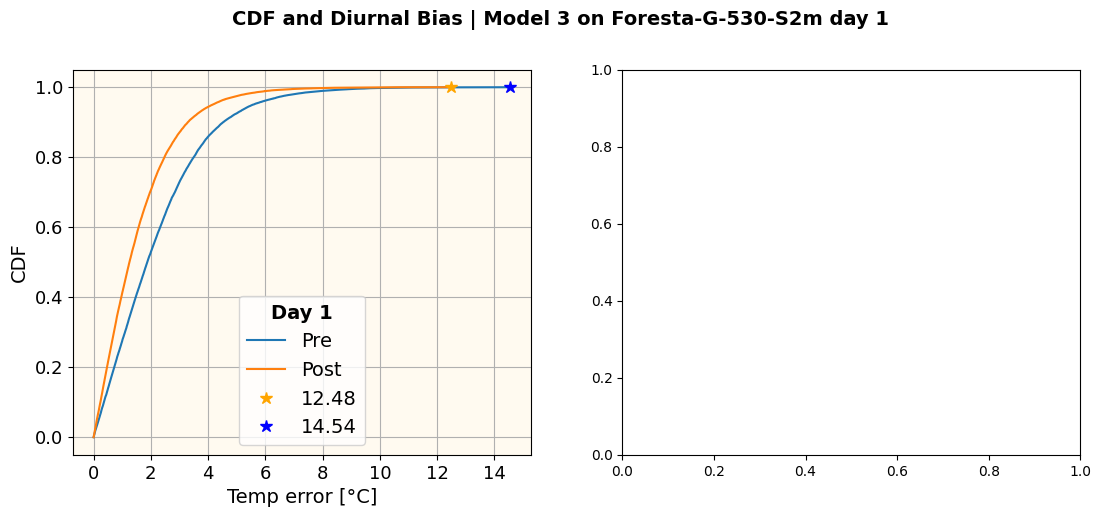

In [ ]:
# Fix this: apparently the plot need the datetime index, so in the shuffle version we need to put it back
# or we find another mwthod to make the agregates by hour, maybe by calculating over certain ranges of day sin or day cos
# or maybe we can add the datetime as a column so when the shuffle is perform we don't loose this information

plot_errors(dff, day, file_name, model_number, save=1, figsize=(13,5))

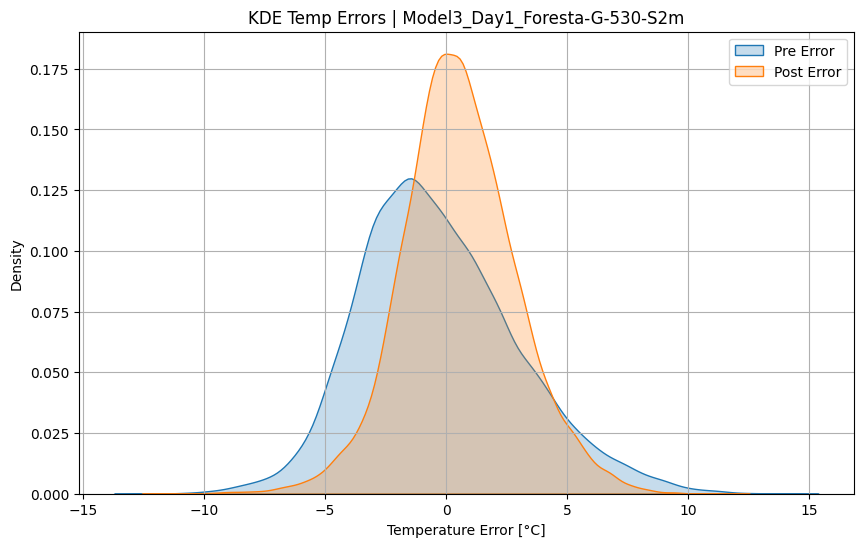

In [ ]:
#Now, as always, we need to make sure the errors of the model are independent and distribute normally
#Let's check both pre and post

import seaborn as sns

plt.figure(figsize=(10, 6))
sns.kdeplot(pre_temp_error, label='Pre Error', fill=True)
sns.kdeplot(post_temp_error, label='Post Error', fill=True)
plt.title(f"KDE Temp Errors | Model{model_number}_Day{day}_{file_name}")
plt.xlabel("Temperature Error [°C]")
plt.ylabel("Density")
plt.legend()
plt.grid()

#save fig
plt.savefig(f"KDE_Model{model_number}_Day{day}_{file_name}.png", dpi=400)

plt.show()
